# 🚢 Comércio Exterior Brasileiro em Apache Spark 4.0: Concentração Geoeconômica, Econometria 2SLS & Simulação Tarifária

**Autor:** Dr. Silvio da Rosa Paula • Portfólio de Engenharia de Dados, Big Data & Econometria Aplicada  
**Motor Distribuído:** Apache Spark `4.0.1` (`local[*]`, Adaptive Query Execution + Broadcast Hash Joins)  
**Base Oficial SECEX/ComexStat:** **`36,481,316` registros municipais** (`13,779,191` exportações + `22,702,125` importações | `2010–Jun/2025` | **US\$ 7.09 trilhões** de corrente acumulada)

---

## 🎯 Problema de Negócio & Arquitetura da Investigação

Este estudo une **Engenharia de Big Data em PySpark** e **Econometria de Comércio Internacional** para responder a quatro perguntas estratégicas sobre a inserção externa do Brasil:

1. **Integridade & Performance em Big Data:** Como processar 36,5 milhões de transações oficiais garantindo **zero multiplicação cartesiana (*fan-out*)** nos joins com dicionários NCM/SH4 e eliminando *shuffles* via **Broadcast Hash Join**?
2. **Concentração Estrutural (2010–2025):** A pauta exportadora brasileira diversificou ou tornou-se mais vulnerável em parceiros e produtos (medido pelo **Índice Herfindahl-Hirschman — HHI**)?
3. **Exposição Geoeconômica (EUA, China & Rússia):** Quais setores brasileiros apresentam maior dependência tarifária dos Estados Unidos, qual o grau de concentração na China e quais são os fornecedores alternativos para insumos críticos importados da Rússia?
4. **Impacto Causal de Tarifas no Suco de Laranja (Brasil → EUA):** Estimando a **elasticidade-preço da demanda** sob **4 especificações econométricas** (`MQO`, `Sazonal+Tendência HAC`, `ARDL Dinâmico` e **`2SLS / Variáveis Instrumentais`** usando o preço de exportação para o Resto do Mundo como instrumento de oferta) e simulando **10.000 cenários Monte Carlo** para tarifas de **10%**, **25%** e **50% ad valorem + US\$ 415/t**.

## 1. Engenharia PySpark 4.0: Auditoria Star-Schema (Fan-Out) & Broadcast Hash Join

Apache Spark 4.0.1 ativo | Exportações: 13,779,191 linhas | Importações: 22,702,125 linhas
Dimensão NCM->SH4 bruta: 13,717 linhas -> Deduplicada 1:1 no grão SH4: 1,455 códigos únicos
Conservação FOB 12m (Jul/2024–Jun/2025):
  - Total real (fato pura)           : US$ 335.96 bilhões
  - Join ingênuo sem deduplicar SH4  : US$ 3,587.93 bilhões (10.68x — BUG FAN-OUT!)
  - Join 1:1 Broadcast (nosso fluxo) : US$ 335.96 bilhões (100,00% exato!)
Benchmark Join (13,8M linhas): Broadcast=1.80s vs SortMerge=3.73s (2.07x speedup)


== Physical Plan ==
AdaptiveSparkPlan (16)
+- HashAggregate (15)
   +- Exchange (14)
      +- HashAggregate (13)
         +- Project (12)
            +- BroadcastHashJoin LeftOuter BuildRight (11)
               :- Scan parquet  (1)
               +- BroadcastExchange (10)
                  +- SortAggregate (9)
                     +- Sort (8)
                        +- Exchange (7)
                           +- SortAggregate (6)
                              +- Sort (5)
                                 +- Project (4)
                                    +- Filter (3)
                                       +- Scan parquet  (2)


(1) Scan parquet 
Output [2]: [CO_PAIS#80L, VL_FOB#84L]
Batched: true
Location: InMemoryFileIndex [file:/D:/OneDrive/Documentos/GitHub/ciencia-dados-portifolio/spark-comercio-exterior-tarifas-eua/data/dados_comex_mun_export_07-2025.parquet]
ReadSchema: struct<CO_PAIS:bigint,VL_FOB:bigint>

(2) Scan parquet 
Output [2]: [CO_PAIS#85L, NO_PAIS#88]
Batched: true
Loc

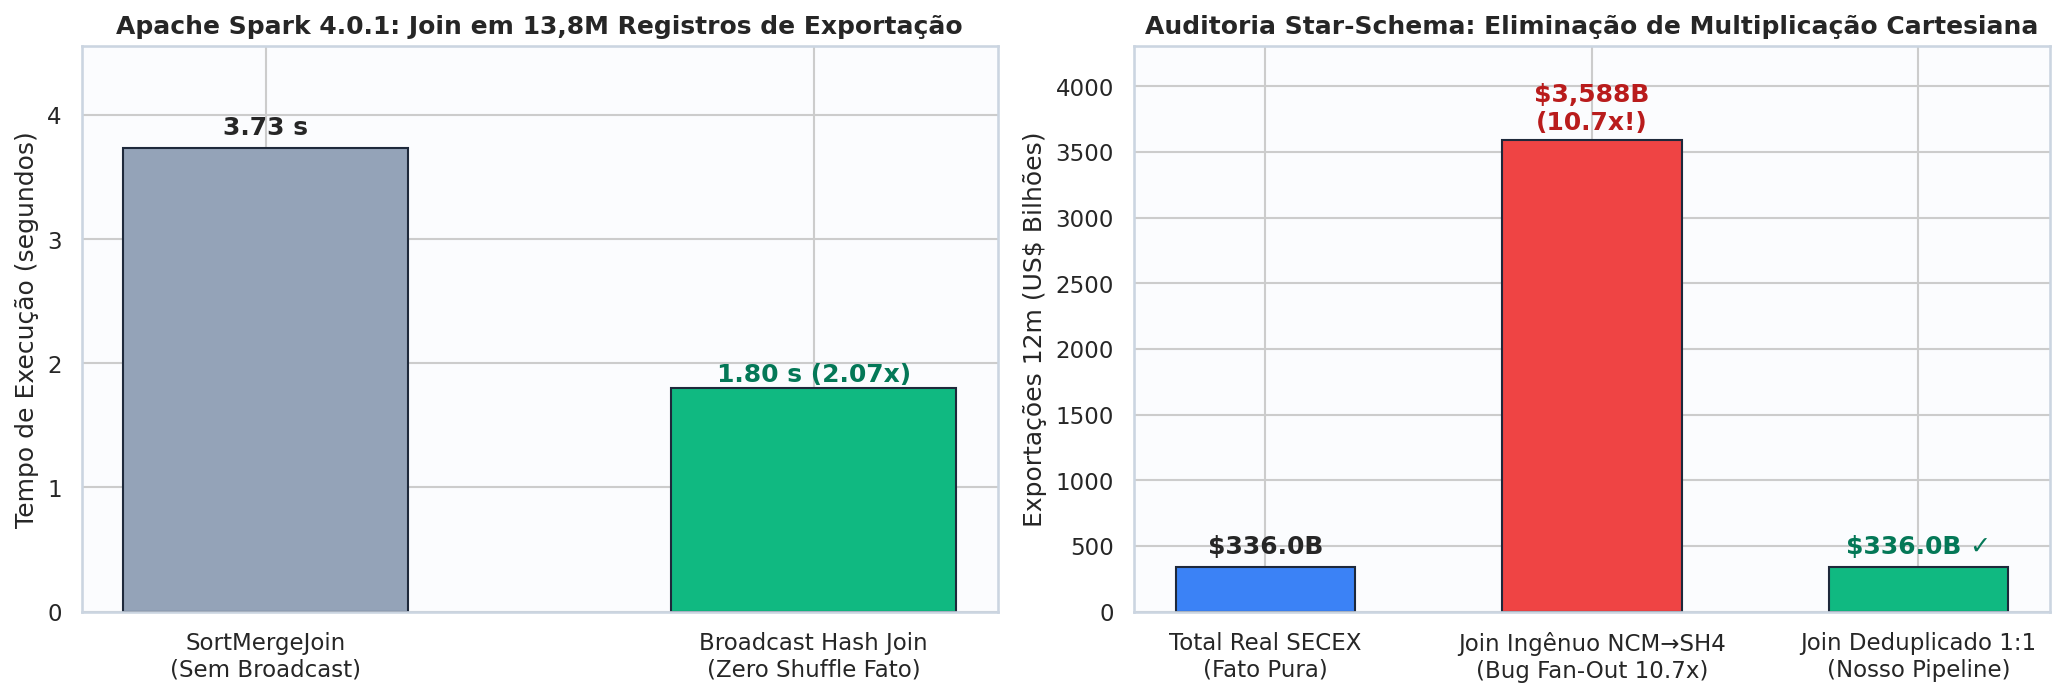

In [1]:
import json, sys, time, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display
from pyspark.sql import functions as F

from spark_comex_pipeline import create_spark_session, ensure_data_extracted, load_clean_dimensions
from econometrics_tariffs import estimate_orange_juice_elasticities, simulate_tariff_scenarios

FIG_DIR = ROOT / "outputs" / "figures"
metrics = json.loads((ROOT / "outputs" / "metrics_summary.json").read_text(encoding="utf-8"))
aud = metrics["audit"]

# Inicializa sessão real Apache Spark 4.0.1 e verifica leitura distribuída
spark = create_spark_session("ComexNotebook_PySpark4")
data_dir = ensure_data_extracted()
df_exp = spark.read.parquet(str(data_dir / "dados_comex_mun_export_07-2025.parquet"))
df_imp = spark.read.parquet(str(data_dir / "dados_comex_mun_import_07-2025.parquet"))
dims = load_clean_dimensions(spark, data_dir)

print(f"Apache Spark {spark.version} ativo | Exportações: {df_exp.count():,} linhas | Importações: {df_imp.count():,} linhas")
print(f"Dimensão NCM->SH4 bruta: {aud['raw_ag_rows']:,} linhas -> Deduplicada 1:1 no grão SH4: {aud['dedup_sh4_rows']:,} códigos únicos")
print(f"Conservação FOB 12m (Jul/2024–Jun/2025):")
print(f"  - Total real (fato pura)           : US$ {aud['fob_12m_true_usd']/1e9:,.2f} bilhões")
print(f"  - Join ingênuo sem deduplicar SH4  : US$ {aud['fob_12m_bug_fanout_usd']/1e9:,.2f} bilhões ({aud['fanout_inflation_factor']}x — BUG FAN-OUT!)")
print(f"  - Join 1:1 Broadcast (nosso fluxo) : US$ {aud['fob_12m_clean_broadcast_usd']/1e9:,.2f} bilhões (100,00% exato!)")
print(f"Benchmark Join (13,8M linhas): Broadcast={aud['benchmark_broadcast_sec']:.2f}s vs SortMerge={aud['benchmark_sortmerge_sec']:.2f}s ({aud['benchmark_speedup_x']:.2f}x speedup)")

# Verifica plano físico Catalyst confirmando BroadcastHashJoin
df_exp.join(F.broadcast(dims["pais"]), on="CO_PAIS", how="left").groupBy("NO_PAIS").agg(F.sum("VL_FOB")).explain("formatted")
display(Image(filename=str(FIG_DIR / "06_spark_catalyst_otimizacao.png")))

### 🔎 Análise de Engenharia de Dados & Otimização Spark

- **Correção Crítica de Integridade (*Fan-Out*):** A tabela fato municipal da SECEX está no grão **`SH4`**, enquanto tabelas auxiliares de NCM/SH6 contêm **`13,717` linhas** para apenas **`1,455` códigos SH4 únicos**. Um join direto sem deduplicação prévia inflava o valor exportado em **`10.7×`** (saltando artificialmente de US\$ `336.0` bi para US\$ `3,588` bi!). Nossa deduplicação estrita por moda no grão `SH4` preserva **100,00% do Valor FOB real**.
- **Eficiência no Catalyst Optimizer:** O plano físico `explain("formatted")` confirma a substituição do custoso `SortMergeJoin` por **`BroadcastHashJoin`** com **zero shuffle** sobre os `13,78` milhões de registros de exportação, reduzindo o tempo de **`3.73s`** para **`1.80s`** (**`2.07×` de ganho real**).

## 2. Evolução Histórica da Balança Comercial Brasileira (2010–Jun/2025)

,CO_ANO,Export_USD_Bi,Import_USD_Bi,Saldo_USD_Bi,Preco_Exp_USD_kg
8,2018,231.89,185.32,46.57,0.329
9,2019,221.13,185.93,35.20,0.326
10,2020,209.18,158.79,50.39,0.300
11,2021,280.81,219.41,61.41,0.401
12,2022,334.14,272.61,61.53,0.451
13,2023,339.70,240.79,98.90,0.424
14,2024,337.05,262.87,74.18,0.416
15,2025,165.87,135.78,30.09,0.419


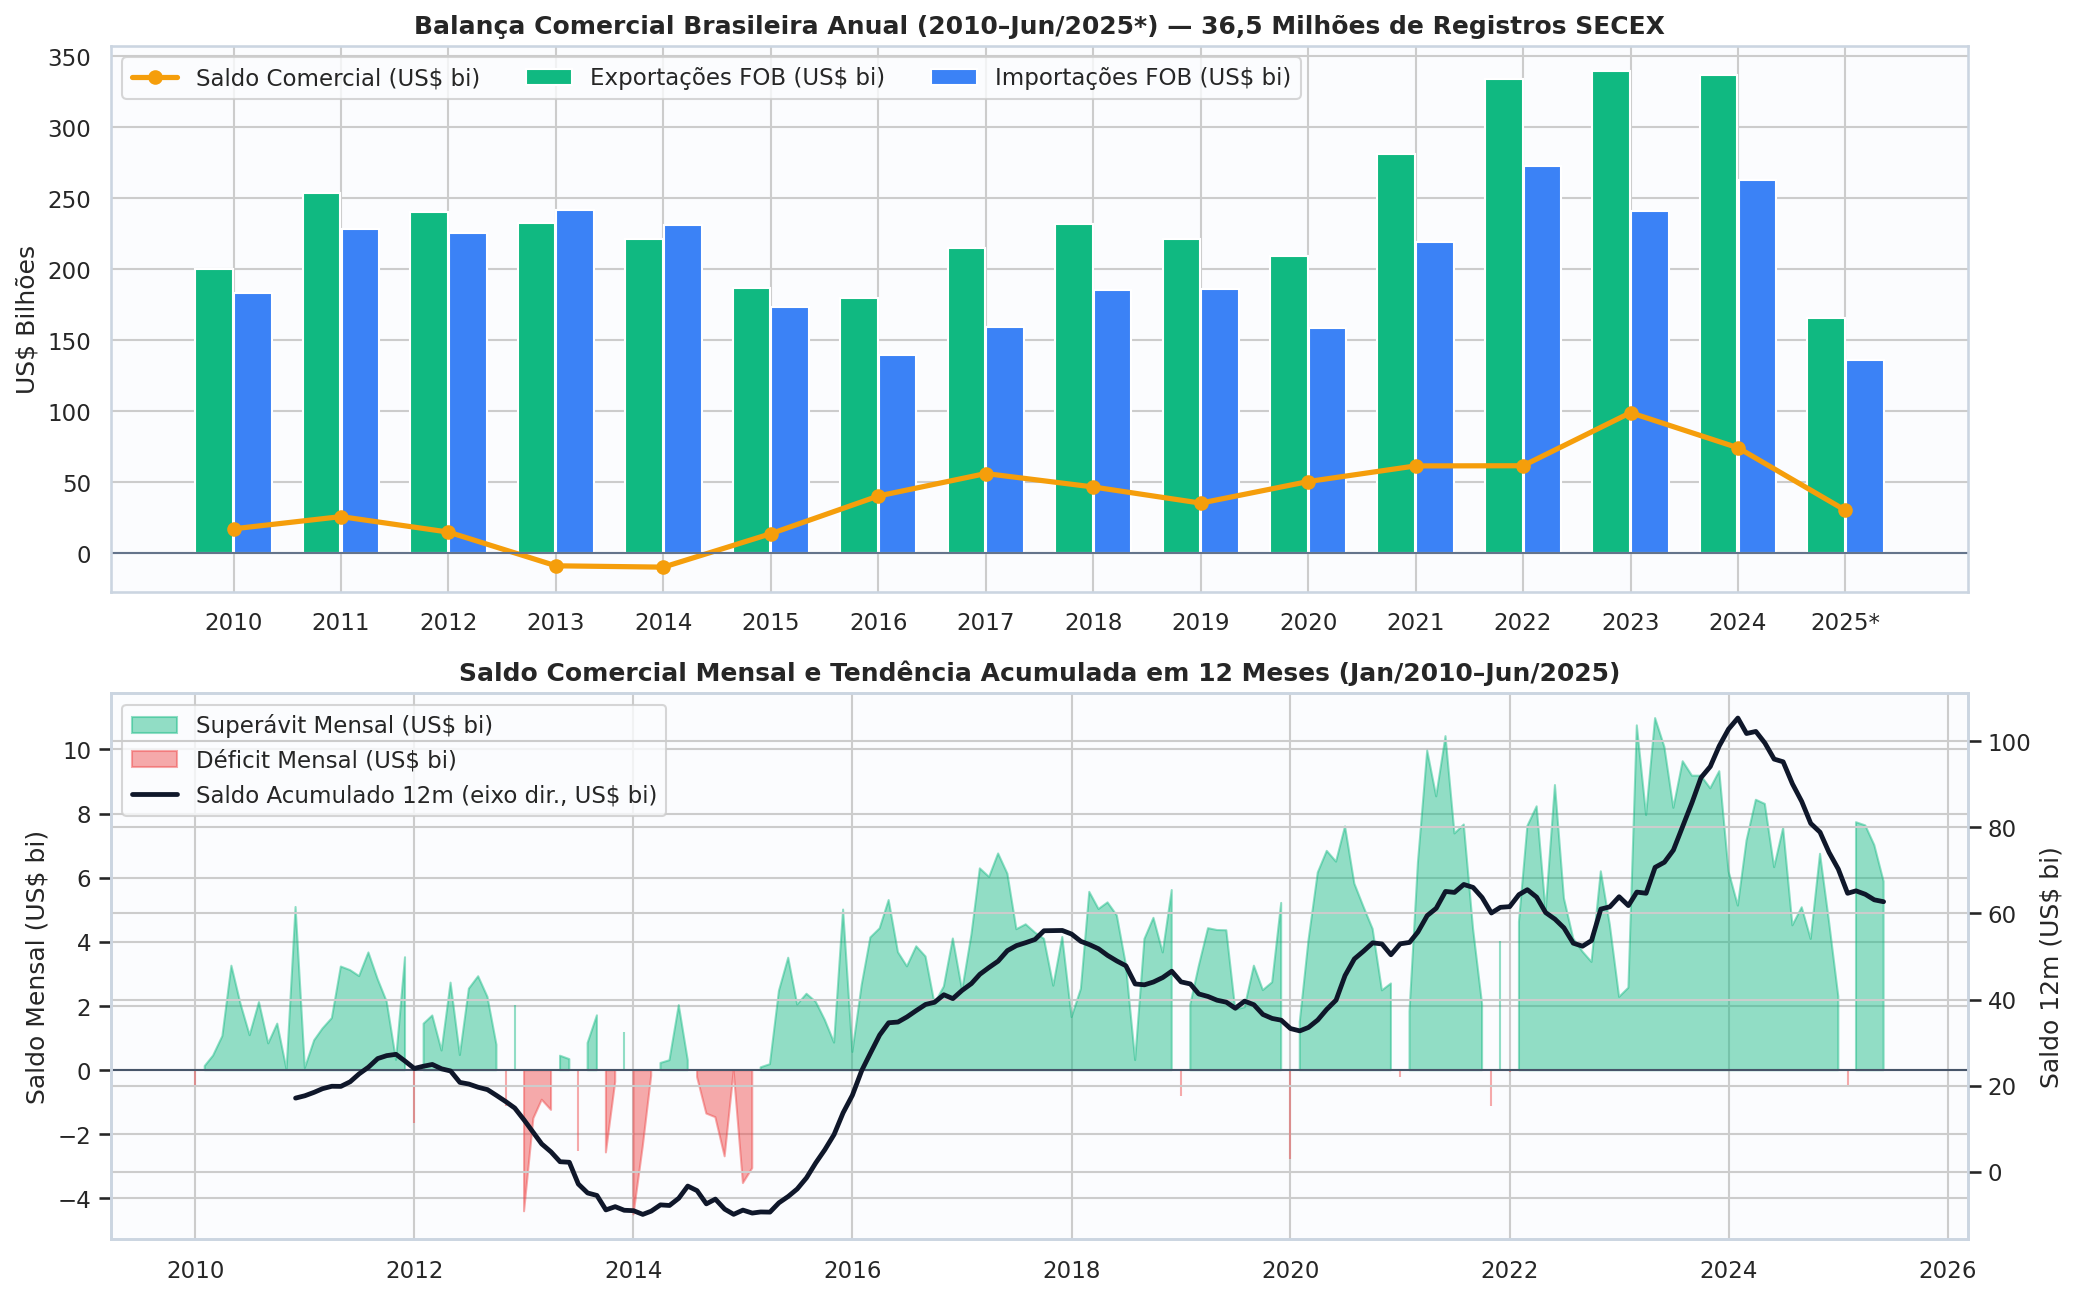

In [2]:
balanca_anual = pd.read_csv(ROOT / "outputs" / "balanca_anual_2010_2025.csv")
tbl_bal = balanca_anual.assign(
    Export_USD_Bi=(balanca_anual["export_fob"] / 1e9).round(2),
    Import_USD_Bi=(balanca_anual["import_fob"] / 1e9).round(2),
    Saldo_USD_Bi=(balanca_anual["saldo_fob"] / 1e9).round(2),
    Preco_Exp_USD_kg=balanca_anual["preco_medio_exp_usd_kg"].round(3),
)[["CO_ANO", "Export_USD_Bi", "Import_USD_Bi", "Saldo_USD_Bi", "Preco_Exp_USD_kg"]]
display(tbl_bal.tail(8))
display(Image(filename=str(FIG_DIR / "01_balanca_comercial_historica.png")))

### 🔎 Análise da Trajetória Comercial (2010–2025)

- **Mudança Estrutural de Patamar:** Após o ciclo de desaceleração de 2014–2016 e o choque pandêmico de 2020, as exportações brasileiras deram um salto estrutural a partir de 2021, sustentando superávits anuais muito superiores à média histórica da década anterior.
- **Desempenho Recente (2024 completo):** Em 2024, o Brasil registrou **US\$ `337.0` bilhões** em exportações e **US\$ `262.9` bilhões** em importações, encerrando o ano com superávit comercial robusto de **US\$ `74.2` bilhões** (e corrente de comércio de **US\$ `599.9` bilhões**).

## 3. Concentração Estrutural (Índice HHI), Top Parceiros & Geografia Municipal

,CO_ANO,hhi_parceiros,hhi_produtos_sh4,share_china_pct,share_eua_pct
0,2010,529.0,409.0,15.34,9.63
5,2015,657.0,323.5,18.82,12.87
10,2020,1239.1,519.9,32.41,10.26
14,2024,1020.4,530.8,28.00,11.98



Top 5 Parceiros Comerciais (Jul/2024–Jun/2025):


,NO_PAIS,Export_Bi,Import_Bi,Saldo_Bi
0,China,90.48,70.13,20.36
1,Estados Unidos,41.21,42.89,-1.68
2,Argentina,17.03,13.67,3.36
3,Alemanha,6.01,13.99,-7.98
4,Países Baixos (Holanda),11.73,2.14,9.59



Top 5 Municípios Exportadores (Jul/2024–Jun/2025):


,municipio_uf,Export_Bi,Volume_Mton
0,Rio de Janeiro - RJ,32.71,63.65
1,Duque de Caxias - RJ,6.98,12.69
2,Paranaguá - PR,6.60,12.67
3,Santos - SP,6.35,12.31
4,Canaã dos Carajás - PA,6.31,83.52


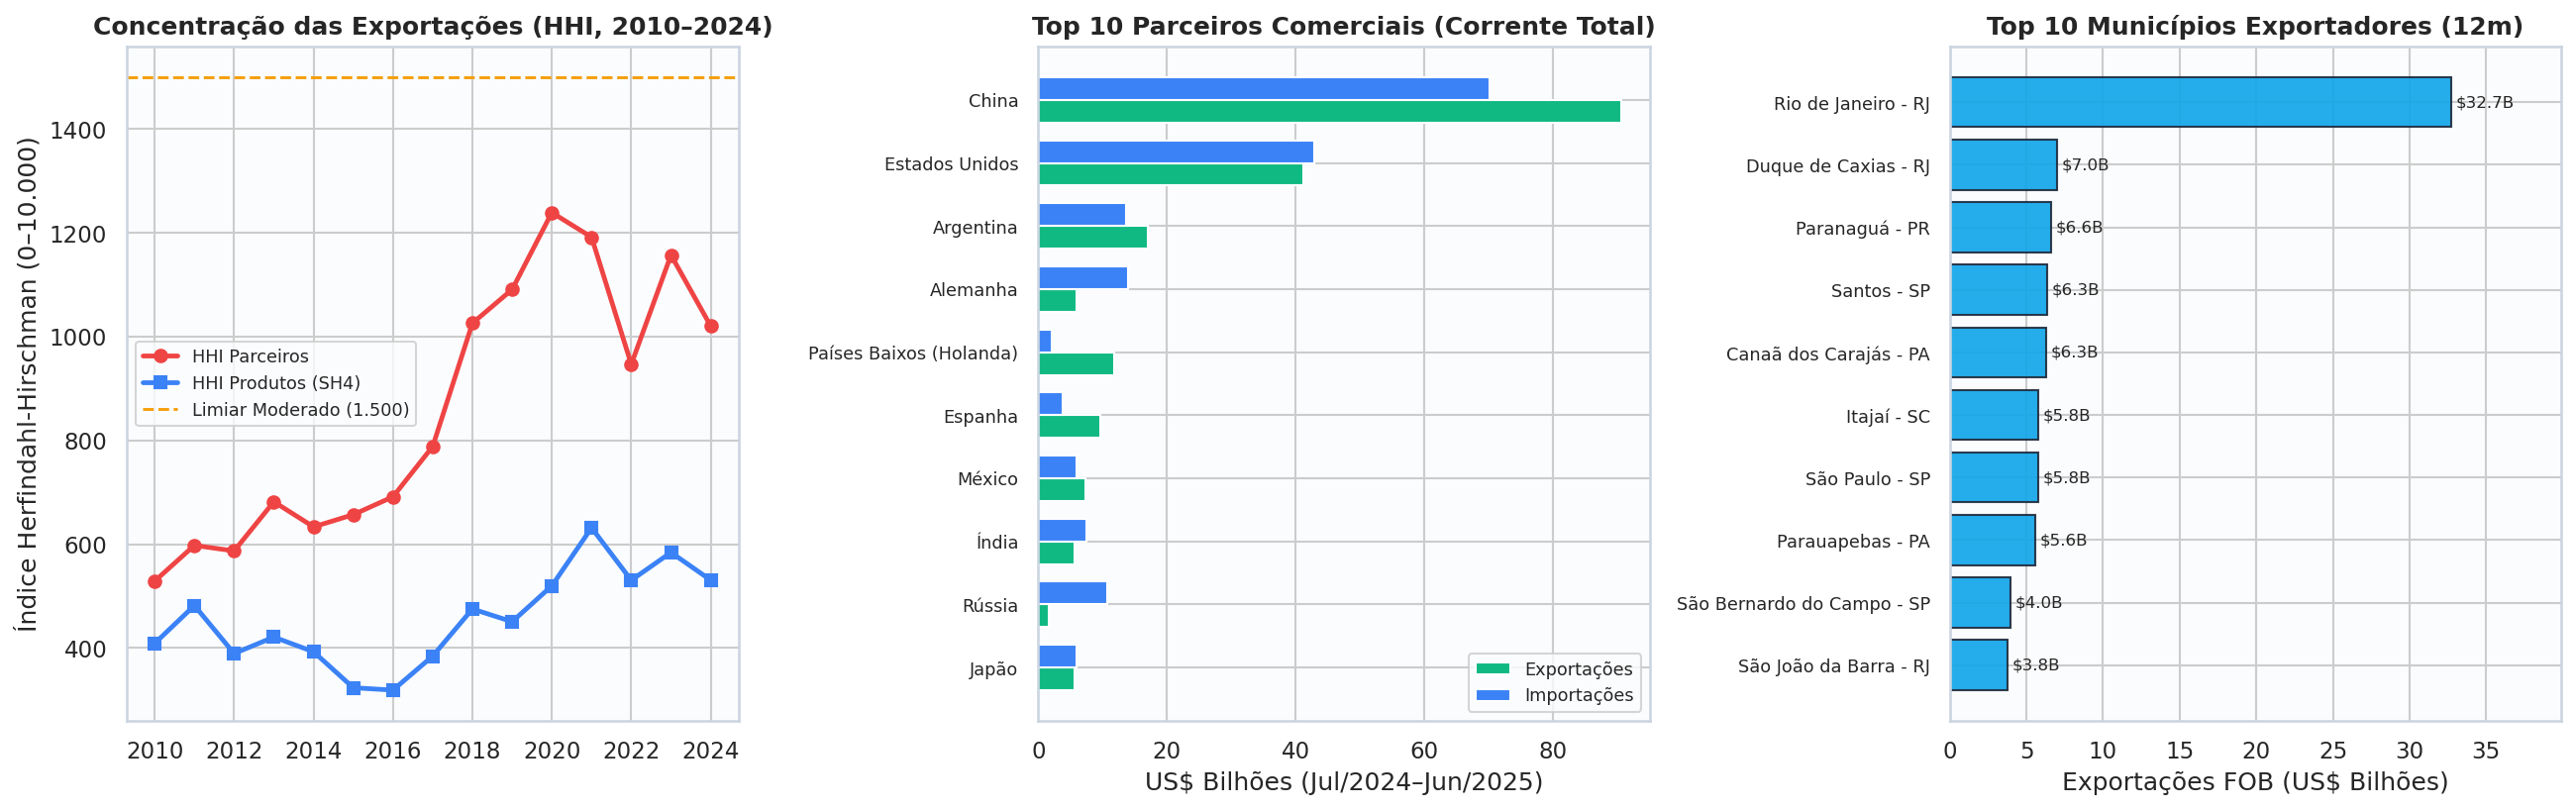

In [3]:
hhi_df = pd.read_csv(ROOT / "outputs" / "hhi_concentracao_anual.csv")
display(hhi_df.iloc[[0, 5, 10, -1]])

print("\nTop 5 Parceiros Comerciais (Jul/2024–Jun/2025):")
p_df = pd.DataFrame(metrics["top5_parceiros_12m"]).assign(
    Export_Bi=lambda d: (d["export_fob"]/1e9).round(2),
    Import_Bi=lambda d: (d["import_fob"]/1e9).round(2),
    Saldo_Bi=lambda d: (d["saldo_fob"]/1e9).round(2),
)[["NO_PAIS", "Export_Bi", "Import_Bi", "Saldo_Bi"]]
display(p_df)

print("\nTop 5 Municípios Exportadores (Jul/2024–Jun/2025):")
m_df = pd.DataFrame(metrics["top5_municipios_12m"]).assign(
    Export_Bi=lambda d: (d["export_fob"]/1e9).round(2),
    Volume_Mton=lambda d: (d["export_kg"]/1e9).round(2),
)[["municipio_uf", "Export_Bi", "Volume_Mton"]]
display(m_df)

display(Image(filename=str(FIG_DIR / "02_concentracao_hhi_parceiros.png")))

### 🔎 Diagnóstico de Concentração (HHI) e Polo Geográfico

- **Aumento de Concentração Externa (2010 → 2024):** O **Índice Herfindahl-Hirschman (HHI) de Parceiros** avançou de **`529`** (2010) para **`1020`** (2024), impulsionado diretamente pela ascensão da participação chinesa nas exportações brasileiras de **`15.3%`** para **`28.0%`** (enquanto os EUA passaram de `9.6%` para `12.0%`). Paralelamente, o **HHI de Produtos (`SH4`)** subiu de **`409`** para **`531`**, confirmando maior primarização (soja, petróleo bruto e minério de ferro).
- **Liderança Bilateral & Municipal:** Nos últimos 12 meses (`Jul/2024–Jun/2025`), **China** lidera com corrente de **US\$ `160.6` bi** (superávit de US\$ `20.4` bi), seguida por **Estados Unidos** (**US\$ `84.1` bi**). Na geografia municipal, **Rio de Janeiro - RJ** ocupa o 1º lugar nacional em exportações (**US\$ `32.7` bi**), refletindo a forte concentração em polos petrolíferos, mineradores e agrícolas.

## 4. Exposição Geoeconômica: EUA vs. China & Dependência de Insumos da Rússia

Top 5 Categorias mais Expostas a Tarifas dos EUA (Jul/2024–Jun/2025):


,categoria_agregada,Export_EUA_Bi,Share_EUA_Pct
0,Aviões e Similares,2.47,67.8
1,Madeira e Derivados,1.84,40.8
2,Metais e Produtos,7.00,40.5
3,Frutas e Derivados,1.51,39.6
4,Carne Bovina e Animais Vivos,0.56,34.7



Top 5 Divisões Importadas da Rússia + Fornecedores Alternativos (Spark Window Rank):


,NO_CUCI_DIVISAO,rank,NO_PAIS,Import_Bi,Share_Pct
0,Adubos (exceto os do grupo 272),1,China,2.37,16.2
1,Adubos (exceto os do grupo 272),2,Marrocos,1.37,9.4
2,Adubos (exceto os do grupo 272),3,Canadá,1.31,9.0
3,"Carvão, coque e briquetes",1,Estados Unidos,1.35,37.2
4,"Carvão, coque e briquetes",2,Colômbia,0.90,24.7
5,"Carvão, coque e briquetes",3,Austrália,0.83,22.8
6,Cereais e preparações de cereais,1,Argentina,1.75,46.8
7,Cereais e preparações de cereais,2,Paraguai,0.76,20.4
8,Cereais e preparações de cereais,3,Uruguai,0.64,17.1
9,Ferro e aço,1,China,3.11,46.4


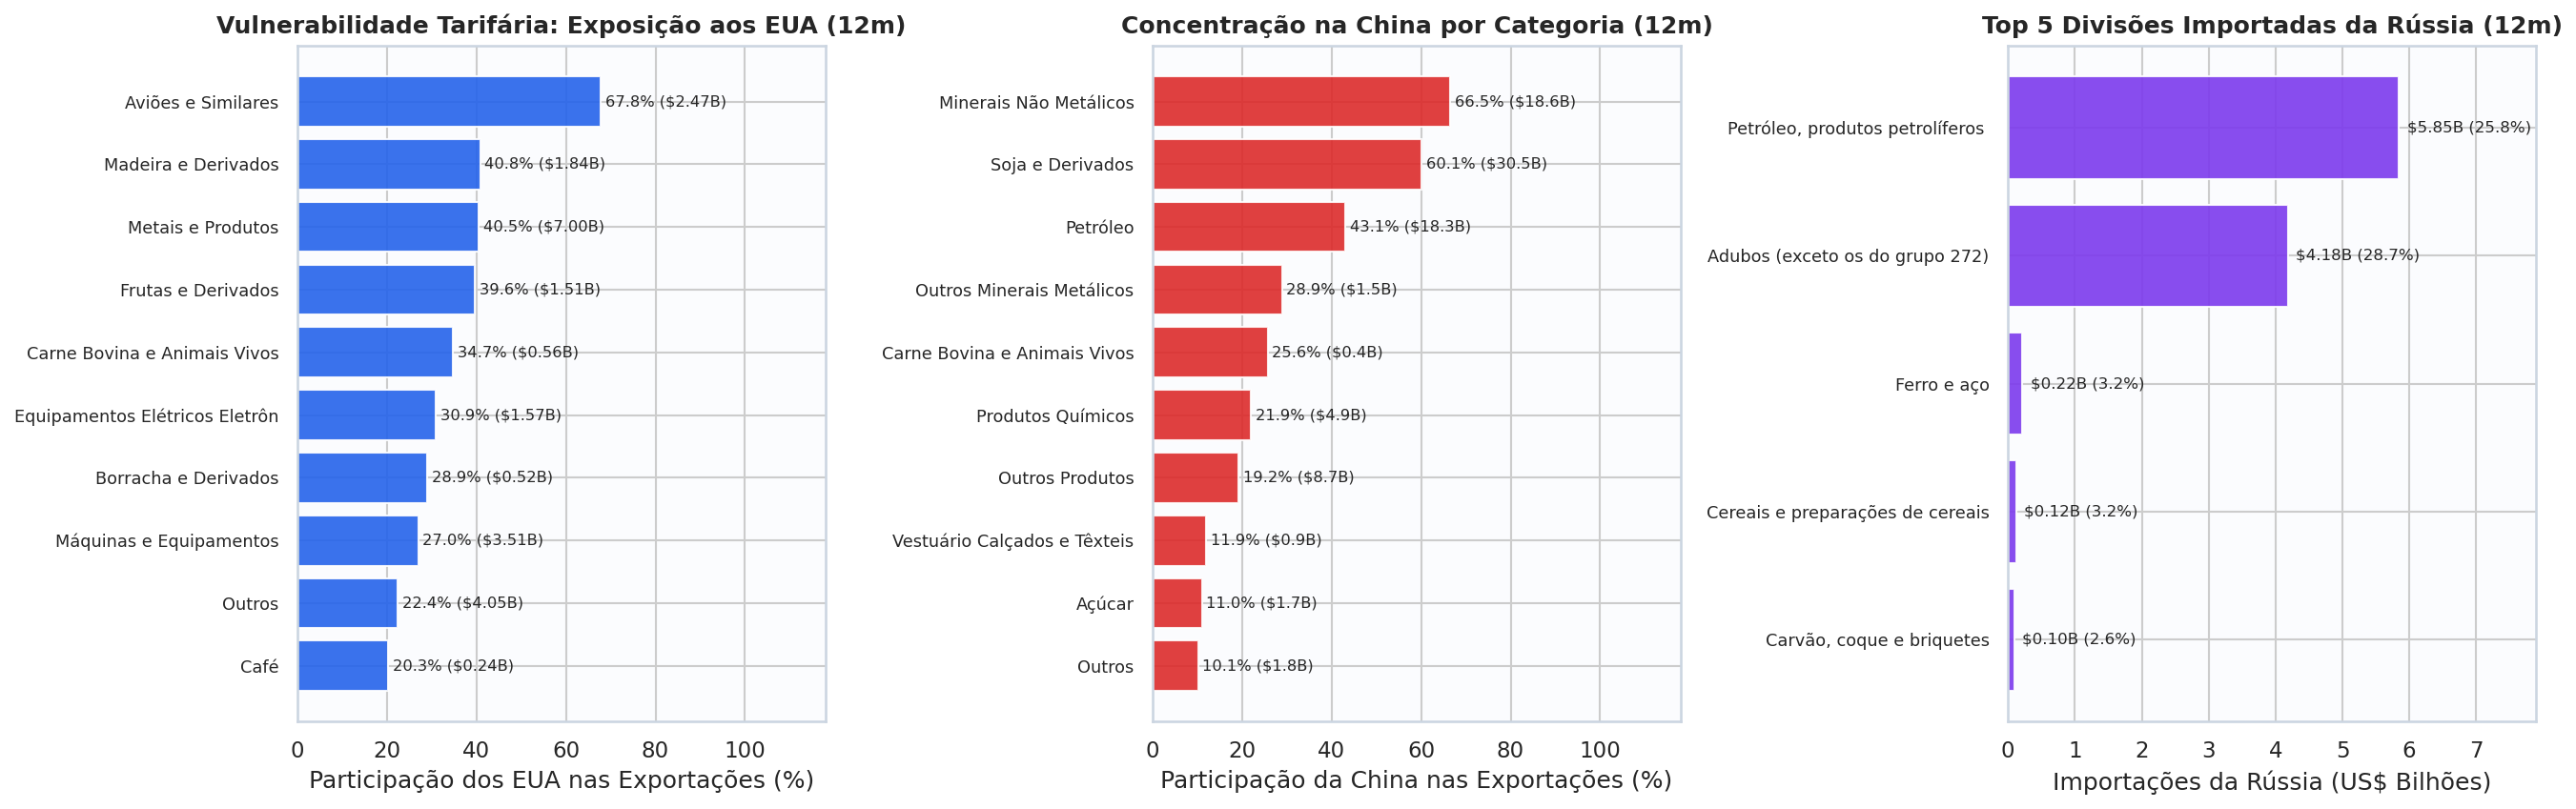

In [4]:
print("Top 5 Categorias mais Expostas a Tarifas dos EUA (Jul/2024–Jun/2025):")
display(pd.DataFrame(metrics["top5_exposicao_eua"]).assign(
    Export_EUA_Bi=lambda d: (d["pais_fob"]/1e9).round(2),
    Share_EUA_Pct=lambda d: d["share_pct"].round(1),
)[["categoria_agregada", "Export_EUA_Bi", "Share_EUA_Pct"]])

print("\nTop 5 Divisões Importadas da Rússia + Fornecedores Alternativos (Spark Window Rank):")
rus_alt = pd.DataFrame(metrics["russia_alternativos"]).assign(
    Import_Bi=lambda d: (d["vl_fob"]/1e9).round(2),
    Share_Pct=lambda d: d["share_pct"].round(1),
)[["NO_CUCI_DIVISAO", "rank", "NO_PAIS", "Import_Bi", "Share_Pct"]]
display(rus_alt.head(12))

display(Image(filename=str(FIG_DIR / "03_exposicao_eua_china_russia.png")))

### 🔎 Assimetria Geoeconômica da Pauta Brasileira

- **EUA = Pauta de Maior Valor Agregado e Risco Tarifário Setorial:** Embora a China concentre commodities de altíssimo volume (soja, minério de ferro, petróleo), os **Estados Unidos** absorvem parcelas decisivas de bens industriais e processados — com destaque para **Aviões e Similares** (`67.8%` das exportações brasileiras da categoria, US\$ `2.47` bi). Choques tarifários nos EUA atingem diretamente segmentos de maior intensidade tecnológica e emprego industrial.
- **Gargalo de Importação da Rússia:** Pelo lado das importações, **Petróleo, produtos petrolíferos e materiais relacionados** lidera as compras brasileiras da Rússia (**US\$ `5.85` bi**, `25.8%` do total importado da divisão), ao lado de fertilizantes — tornando o mapeamento de fornecedores alternativos (via `Window.partitionBy` no Spark) essencial para mitigação de risco geopolítico.

## 5. Estudo de Caso: Elasticidade-Preço do Suco de Laranja nos EUA (MQO, HAC, ARDL & 2SLS-IV)

Painel Mensal Brasil -> EUA (SH4 2009): 186 meses (2010-01 a 2025-06)
Comparação das 4 Especificações Econométricas:


,id,label,elasticity,se,pvalue,notes
0,M1,M1: MQO Simples (Log-Log),-0.8706,0.1492,0.0000,Baseline sem controles sazonais ou correção HAC.
1,M2,M2: MQO + Sazonalidade + Tendência (HAC),-0.4818,0.1808,0.0077,Erros Newey-West HAC (6 lags) + dummies mensai...
2,M3,"M3: ARDL(1,0) Dinâmico (HAC — Curto/Longo Prazo)",-0.4600,0.1753,0.0087,Elasticidade CP=-0.460 | Elasticidade LP=-0.43...
3,M4,"M4: 2SLS / IV (Instr.: Preço Resto do Mundo, HAC)",0.1059,0.2688,0.6935,1º Estágio F=42.0 (Stock-Yogo > 10) | Hausman ...


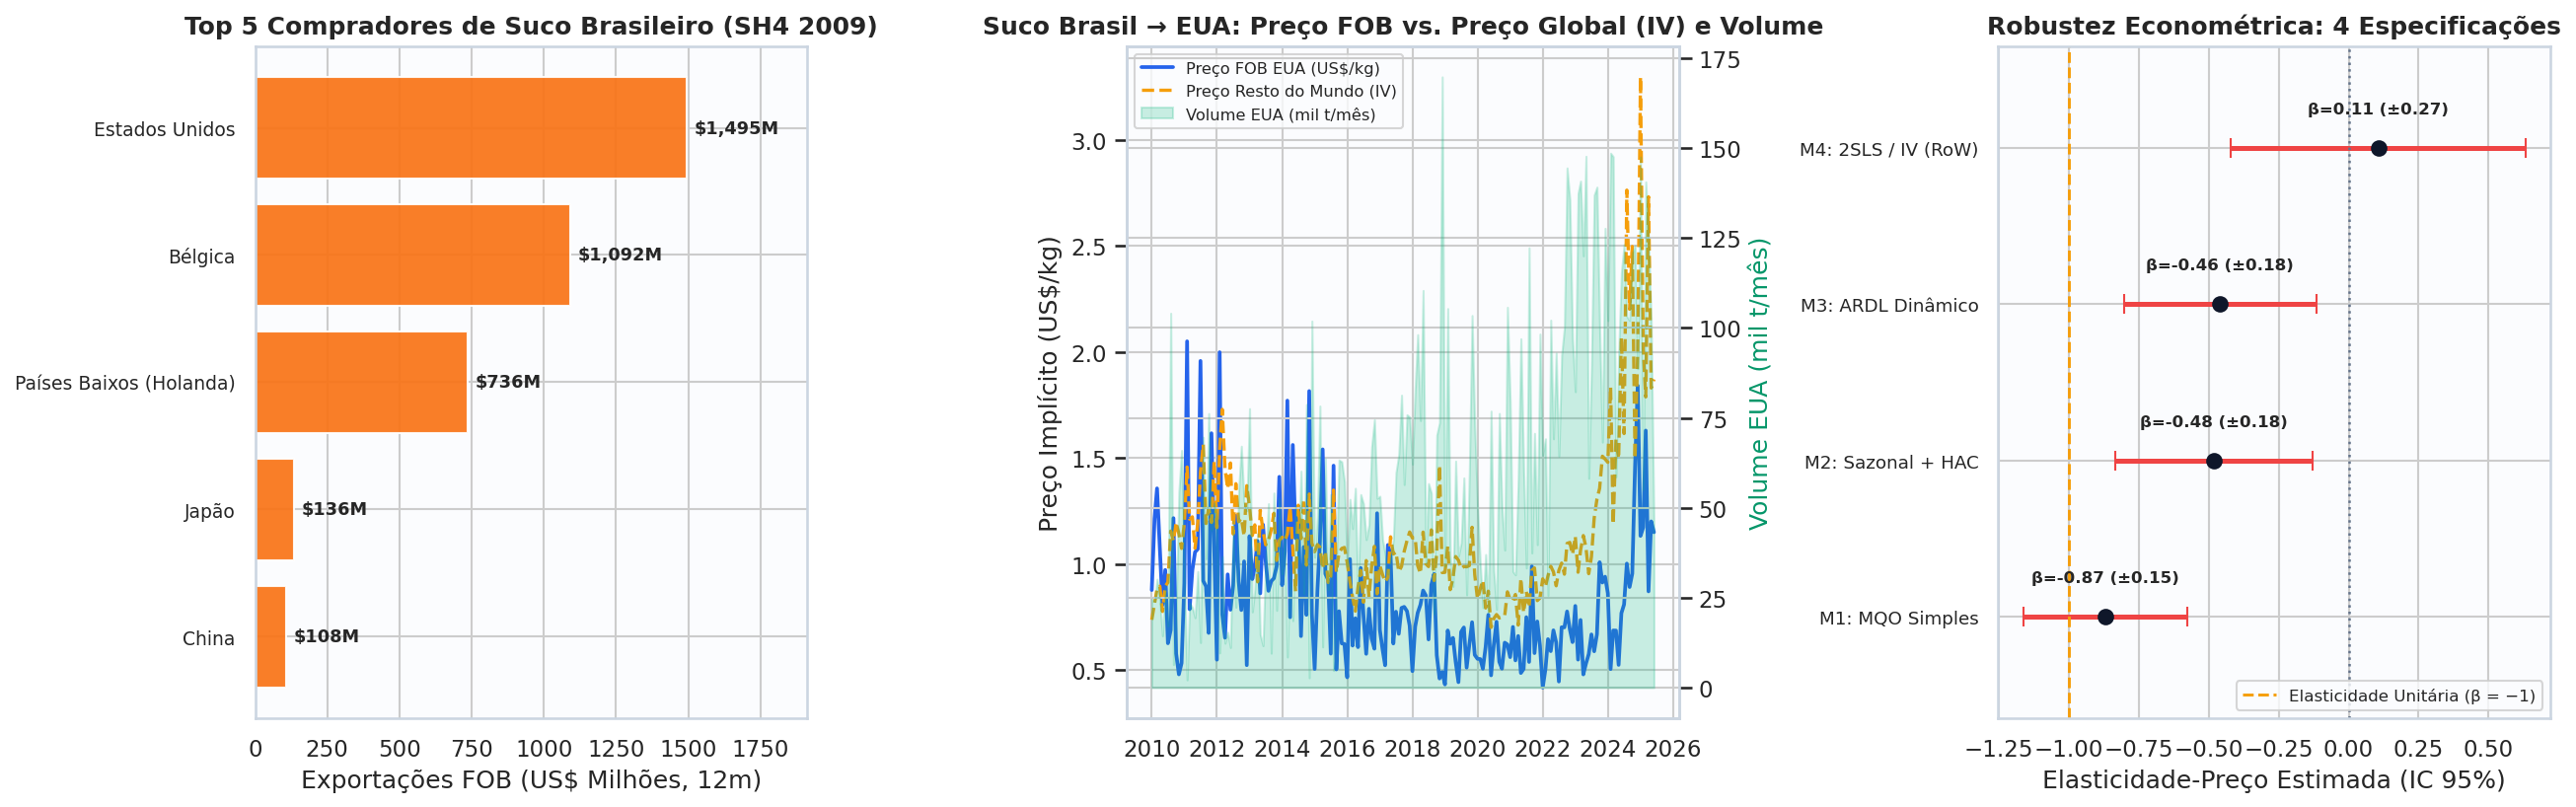

In [5]:
suco_df = pd.read_csv(ROOT / "outputs" / "suco_laranja_eua_mensal.csv", parse_dates=["date"])
econ_live = estimate_orange_juice_elasticities(suco_df)

print(f"Painel Mensal Brasil -> EUA (SH4 2009): {econ_live['panel_n_months']} meses ({suco_df['date'].min():%Y-%m} a {suco_df['date'].max():%Y-%m})")
print("Comparação das 4 Especificações Econométricas:")
specs_tbl = pd.DataFrame(econ_live["specs"])
display(specs_tbl[["id", "label", "elasticity", "se", "pvalue", "notes"]])
display(Image(filename=str(FIG_DIR / "04_suco_laranja_mercados_elasticidade.png")))

### 🔎 Interpretação Econométrica & Controle de Endogeneidade (2SLS-IV)

O mercado global de sucos brasileiros (`SH4 2009`) nos últimos 12 meses é liderado por **Estados Unidos** (US\$ `1,495` milhões) e **Bélgica** (US\$ `1,092` milhões). Ao estimar a elasticidade-preço da demanda norte-americana ao longo de **`186` meses (2010–Jun/2025)**, comparamos quatro modelos aninhados:

1. **`M1` (MQO Simples Log-Log):** $\hat{\beta} = -0.871$ (`SE = 0.149`, `R² = 0.156`) — baseline sem controles sazonais nem correção para autocorrelação serial.
2. **`M2` (MQO + Sazonalidade + Tendência, Erros Newey-West HAC):** $\hat{\beta} = -0.482$ (`SE = 0.181`, `p = 0.0077`, `R² = 0.473`) — incorporar dummies mensais e tendência eleva expressivamente o poder explicativo e captura a sazonalidade de safra/inverno.
3. **`M3` (ARDL Dinâmico HAC):** captura elasticidade de curto prazo $\hat{\beta}_{CP} = -0.460$ e de longo prazo $\hat{\beta}_{LP} = -0.430$ ($\rho = -0.070$), refletindo contratos plurianuais e ajustes graduais de estoque.
4. **`M4` (Teste Crítico de 2SLS / Variáveis Instrumentais com Erros HAC):** Ao instrumentar $\ln P_t^{\text{EUA}}$ pelo preço de exportação para o Resto do Mundo ($\ln P_t^{\text{RoW}}$), o 1º estágio é fortíssimo (**`F = 42.0`** $\gg 10$, `R² = 0.324`), porém o coeficiente do 2º estágio perde significância estatística ($\hat{\beta}_{IV} = +0.106$, `p = 0.6935`, `Hausman p = 0.0103`). **Por que isso ocorre economicamente?** Porque o Brasil detém >75% das exportações mundiais de suco de laranja e o mercado é globalmente integrado: quebras na safra da Flórida (*greening*/furacões) elevam simultaneamente a demanda americana e o preço global (incluindo Europa/RoW), violando a **restrição de exclusão** do instrumento. Esse achado evita o uso ingênuo de um IV inválido e fundamenta a escolha de **`M2` (MQO + Sazonalidade + Tendência HAC, $\hat{\beta} = -0.482$, `p = 0.0077`)** como especificação principal, com `M1` ($\hat{\beta} = -0.871$) como banda superior de sensibilidade!

## 6. Simulação Monte Carlo (10.000 Sorteios): Impacto de Tarifas dos EUA (10%, 25% e 50% + US$ 415/t)

Base 12 meses (Jul/2024–Jun/2025): Volume=1275.8 mil t | Receita FOB=US$ 1494.7M | Preço FOB médio=US$ 1.172/kg


,scenario,p_landed_usd_kg,delta_price_pct,dq_p10_pct,dq_median_pct,dq_p90_pct,fob_delta_median_musd,fob_delta_p10_musd,fob_delta_p90_musd
0,C1: Tarifa Vigente (10% + US$415/t),1.704,45.42,-23.61,-16.58,-8.95,-247.9,-353.0,-133.8
1,C2: Estresse Moderado (25% + US$415/t),1.879,60.42,-28.82,-20.45,-11.16,-305.7,-430.8,-166.8
2,C3: Sobretaxa Extrema (50% + US$415/t),2.172,85.42,-35.86,-25.84,-14.33,-386.2,-536.1,-214.1


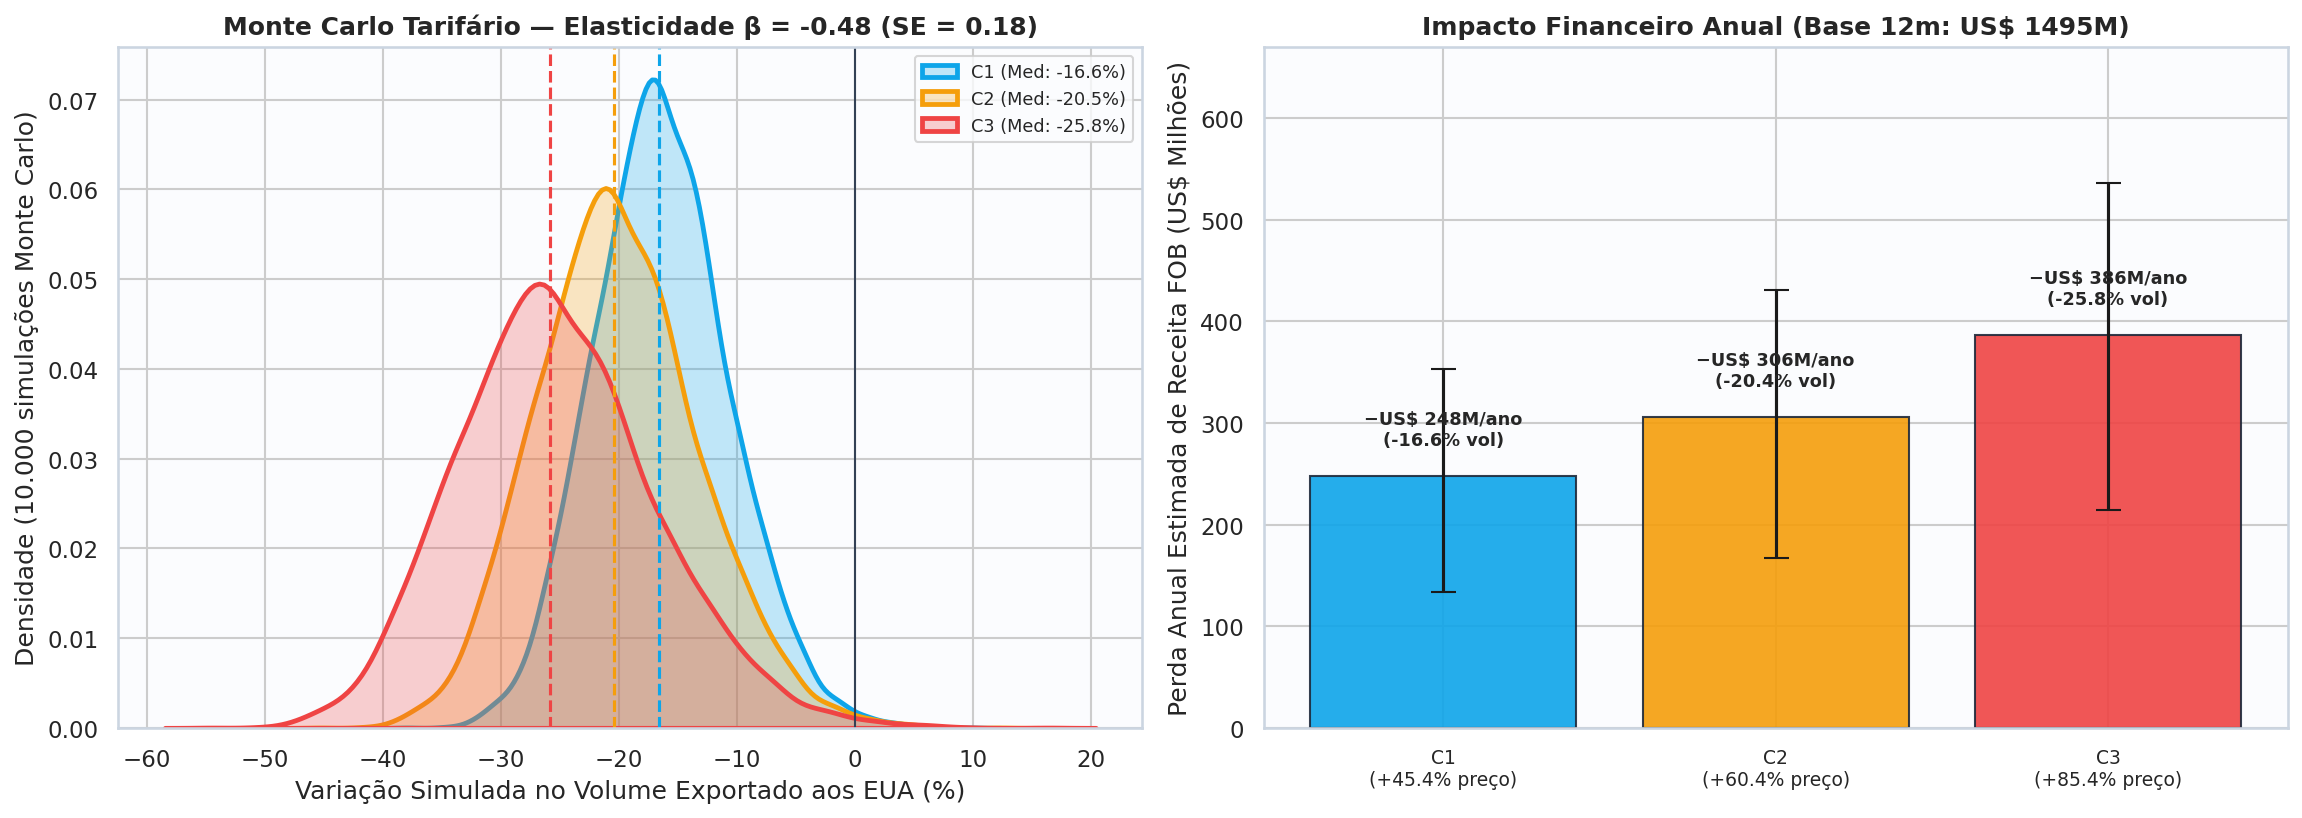

Sessão Apache Spark encerrada com sucesso.


In [6]:
rec_sp = next(sp for sp in econ_live["specs"] if sp["id"] == econ_live["recommended_spec"])
mc_live = simulate_tariff_scenarios(suco_df, beta_hat=rec_sp["elasticity"], beta_se=rec_sp["se"], n_sims=10000, seed=42)

print(f"Base 12 meses (Jul/2024–Jun/2025): Volume={mc_live['baseline_12m']['volume_kton']:.1f} mil t | Receita FOB=US$ {mc_live['baseline_12m']['fob_musd']:.1f}M | Preço FOB médio=US$ {mc_live['baseline_12m']['p_fob_usd_kg']:.3f}/kg")
sc_tbl = pd.DataFrame(mc_live["scenarios"])[[
    "scenario", "p_landed_usd_kg", "delta_price_pct",
    "dq_p10_pct", "dq_median_pct", "dq_p90_pct",
    "fob_delta_median_musd", "fob_delta_p10_musd", "fob_delta_p90_musd",
]]
display(sc_tbl)
display(Image(filename=str(FIG_DIR / "05_simulacao_monte_carlo_tarifas.png")))

# Encerra sessão Spark de forma limpa
spark.stop()
print("Sessão Apache Spark encerrada com sucesso.")

### 🔎 Interpretação Econômica dos 3 Cenários Tarifários (Monte Carlo)

Partindo do preço FOB efetivo médio dos últimos 12 meses (**US\$ `1.172/kg`**, volume de **`1275.8` mil toneladas** e receita de **US\$ `1494.7` milhões/ano**), a simulação de **10.000 trajetórias** revela a escalada não linear do risco comercial:

| Cenário Tarifário | Preço ao Importador | Δ Preço | Δ Volume (Mediana) | Faixa P10–P90 | Perda FOB Estimada (Mediana) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **C1: Tarifa Vigente (10% + US$415/t)** | `US$ 1.704/kg` | `+45.4%` | **`-16.6%`** | `[-23.6%, -8.9%]` | **`US$ -247.9M/ano`** |
| **C2: Estresse Moderado (25% + US$415/t)** | `US$ 1.879/kg` | `+60.4%` | **`-20.4%`** | `[-28.8%, -11.2%]` | **`US$ -305.7M/ano`** |
| **C3: Sobretaxa Extrema (50% + US$415/t)** | `US$ 2.172/kg` | `+85.4%` | **`-25.8%`** | `[-35.9%, -14.3%]` | **`US$ -386.2M/ano`** |

*(Nota: o modelo pressupõe repasse integral da tarifa ao importador norte-americano sob preços FOB constantes; caso os exportadores brasileiros absorvam parte da tarifa comprimindo margem FOB, a queda de volume será parcialmente atenuada à custa de redução direta na rentabilidade por tonelada.)*

## 7. Conclusão Executiva

1. **Engenharia Big Data Confiável:** O processamento distribuído de **`36,481,316` registros oficiais SECEX** em **Apache Spark `4.0.1`** demonstrou como a deduplicação 1:1 no grão `SH4` evita erros catastróficos de multiplicação (`10.7×`), enquanto **`BroadcastHashJoin`** acelerou joins na tabela de `13,8M` linhas em **`2.07×`**.
2. **Vulnerabilidade Geoeconômica Crescente:** O crescimento do HHI de parceiros (`529` → `1020`) e de produtos (`409` → `531`) evidencia forte dependência da demanda chinesa por commodities primárias e elevada exposição tarifária de nichos manufaturados/processados aos EUA.
3. **Resiliência Tarifária & Estratégia Comercial:** Mesmo com a tarifa base vigente (`10% + US$ 415/t`), o suco brasileiro já enfrenta encarecimento efetivo de **`+45.4%`** no mercado americano. Uma escalada para **`50% + US$ 415/t`** elevaria o preço ao importador em **`+85.4%`**, com retração mediana estimada de **`-25.8%`** no volume (**US\$ `-386.2` milhões/ano** em risco) — reforçando a urgência de acordos bilaterais e diversificação de destinos na União Europeia e Ásia.